In [35]:
import pandas as pd
from pathlib import Path

racine = Path.cwd()
while not (racine / "data" / "raw").exists() and racine != racine.parent:
    racine = racine.parent

fichiers = sorted((racine / "data" / "raw").glob("*.csv.gz"))
df = pd.concat((pd.read_csv(f, low_memory=False) for f in fichiers), ignore_index=True)
print(f"Lignes brutes : {len(df):,}")

Lignes brutes : 1,720,509


In [36]:
# On écarte les échanges, adjudications, ventes en l'état futur d'achèvement (VEFA), etc.
ventes = df[df["nature_mutation"] == "Vente"].copy()
print(f"Lignes 'Vente' : {len(ventes):,}")
print(f"Ventes uniques : {ventes['id_mutation'].nunique():,}")

Lignes 'Vente' : 1,576,006
Ventes uniques : 630,880


In [37]:
# Les lignes sans type_local sont du terrain nu : on les met de côté pour l'instant
# On supprime les doublons d'un même bien répété à cause des natures de culture
locaux = ventes.dropna(subset=["type_local"]).drop_duplicates(
    subset=["id_mutation", "id_parcelle", "type_local",
            "surface_reelle_bati", "nombre_pieces_principales", "lot1_numero"]
)

# Pour chaque vente : combien de maisons, d'appartements, de dépendances, d'autres locaux ?
comptes = locaux.groupby("id_mutation")["type_local"].value_counts().unstack(fill_value=0)
print(comptes.columns.tolist())
comptes.head()

['Appartement', 'Dépendance', 'Local industriel. commercial ou assimilé', 'Maison']


type_local,Appartement,Dépendance,Local industriel. commercial ou assimilé,Maison
id_mutation,,,,
2021-1397162,0,0,0,1
2021-1397163,0,1,0,1
2021-1397164,0,0,0,1
2021-1397165,0,0,0,1
2021-1397166,2,1,0,0


In [38]:
#garder les ventes d’un seul logement (piège n°1)
nb_logements = comptes.get("Maison", 0) + comptes.get("Appartement", 0)
nb_dependances = comptes.get("Dépendance", 0)
nb_autres = comptes.sum(axis=1) - nb_logements - nb_dependances  # locaux commerciaux, etc.

ventes_simples = comptes.index[(nb_logements == 1) & (nb_autres == 0)]
print(f"Ventes d'un seul logement : {len(ventes_simples):,} "
      f"sur {len(comptes):,} ventes avec au moins un bâtiment")

Ventes d'un seul logement : 450,363 sur 560,698 ventes avec au moins un bâtiment


In [39]:
#tableau final : une ligne par vente
colonnes = ["id_mutation", "date_mutation", "valeur_fonciere", "type_local",
            "surface_reelle_bati", "nombre_pieces_principales",
            "code_postal", "code_commune", "nom_commune", "code_departement",
            "longitude", "latitude"]

logements = locaux[
    locaux["type_local"].isin(["Maison", "Appartement"])
    & locaux["id_mutation"].isin(ventes_simples)
][colonnes].set_index("id_mutation")

# Nombre de dépendances (caves, garages...) : ce sera une variable du modèle
logements["nb_dependances"] = nb_dependances.reindex(logements.index).fillna(0).astype(int)

# Surface de terrain totale de la vente, sans compter deux fois la même parcelle
terrain = (
    ventes.drop_duplicates(subset=["id_mutation", "id_parcelle", "code_nature_culture", "surface_terrain"])
    .groupby("id_mutation")["surface_terrain"].sum()
)
logements["surface_terrain"] = terrain.reindex(logements.index).fillna(0)
# Pour un appartement, le terrain est celui de toute la copropriété : sans intérêt
logements.loc[logements["type_local"] == "Appartement", "surface_terrain"] = 0

logements["date_mutation"] = pd.to_datetime(logements["date_mutation"])

print(f"Une ligne par vente ? {logements.index.is_unique}")
print(f"Logements : {len(logements):,}")
logements.head()

Une ligne par vente ? True
Logements : 450,363


,date_mutation,valeur_fonciere,type_local,surface_reelle_bati,nombre_pieces_principales,code_postal,code_commune,nom_commune,code_departement,longitude,latitude,nb_dependances,surface_terrain
id_mutation,,,,,,,,,,,,,
2021-40424,2021-01-05,81960.0,Appartement,28.0,1.0,4800.0,4094,Gréoux-les-Bains,4,5.894395,43.759373,0,0.0
2021-40426,2021-01-05,405500.0,Maison,86.0,3.0,4400.0,4226,Uvernet-Fours,4,6.610453,44.359152,0,401.0
2021-40428,2021-01-07,20000.0,Maison,65.0,2.0,4380.0,4217,Thoard,4,6.147419,44.149455,0,29.0
2021-40429,2021-01-07,254000.0,Appartement,68.0,4.0,4260.0,4006,Allos,4,6.623223,44.243794,2,0.0
2021-40430,2021-01-05,233000.0,Maison,112.0,3.0,5110.0,4066,Curbans,4,6.039241,44.429802,0,592.0


In [40]:
#supprimer valeurs absurdes
avant = len(logements)

logements = logements.dropna(subset=["valeur_fonciere", "surface_reelle_bati", "longitude", "latitude"])
logements = logements[
    (logements["valeur_fonciere"] >= 10_000)          # ventes symboliques
    & (logements["surface_reelle_bati"] >= 9)         # erreurs de saisie
    & (logements["nombre_pieces_principales"] >= 1)
]

# Prix au m² : on retire les 1 % les plus extrêmes de chaque côté, par type de bien
logements["prix_m2"] = logements["valeur_fonciere"] / logements["surface_reelle_bati"]
bas = logements.groupby("type_local")["prix_m2"].transform(lambda s: s.quantile(0.01))
haut = logements.groupby("type_local")["prix_m2"].transform(lambda s: s.quantile(0.99))
logements = logements[(logements["prix_m2"] >= bas) & (logements["prix_m2"] <= haut)]

print(f"Supprimés : {avant - len(logements):,} ({(avant - len(logements)) / avant:.1%})")
print(f"Restants : {len(logements):,}")
logements.groupby("type_local")["prix_m2"].describe()

Supprimés : 16,274 (3.6%)
Restants : 434,089


,count,mean,std,min,25%,50%,75%,max
type_local,,,,,,,,
Appartement,290404.0,3946.638402,1846.864915,724.637681,2575.757576,3680.000000,4991.995727,11515.151515
Maison,143685.0,4304.390309,2365.259526,666.666667,2780.000000,3823.529412,5208.333333,17571.428571


In [41]:
#sauvegarder le résultat
dossier_sortie = racine / "data" / "processed"
dossier_sortie.mkdir(exist_ok=True)
logements.to_parquet(dossier_sortie / "logements_paca.parquet")
print("Sauvegardé !")

Sauvegardé !


In [44]:
print(f"Dossier des figures : {dossier_fig}")
print(f"Images trouvées : {[f.name for f in dossier_fig.glob('*.png')]}")

Dossier des figures : c:\Users\salwa\estimateur-immo-dvf\figures
Images trouvées : ['carte_prix_m2.png', 'test.png']


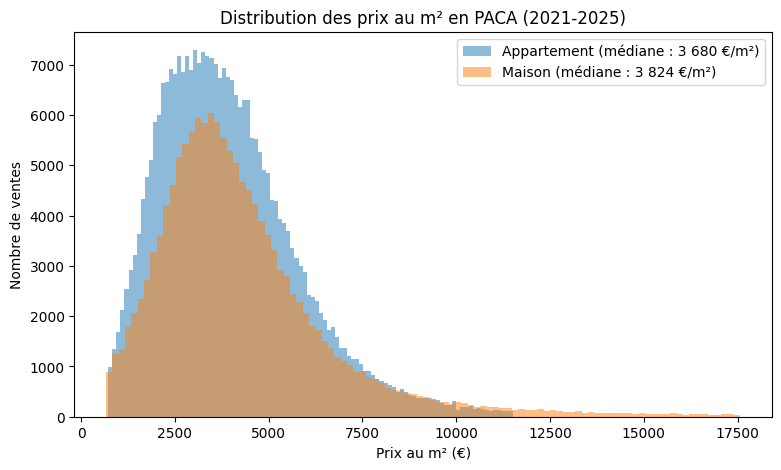

In [45]:
fig, ax = plt.subplots(figsize=(9, 5))
for type_local, couleur in [("Appartement", "tab:blue"), ("Maison", "tab:orange")]:
    s = logements.loc[logements["type_local"] == type_local, "prix_m2"]
    ax.hist(s, bins=100, alpha=0.5, color=couleur,
            label=f"{type_local} (médiane : {s.median():,.0f} €/m²)".replace(",", " "))
ax.set(title="Distribution des prix au m² en PACA (2021-2025)",
       xlabel="Prix au m² (€)", ylabel="Nombre de ventes")
ax.legend()
fig.savefig(dossier_fig / "distribution_prix_m2.png", dpi=150, bbox_inches="tight")
plt.show()

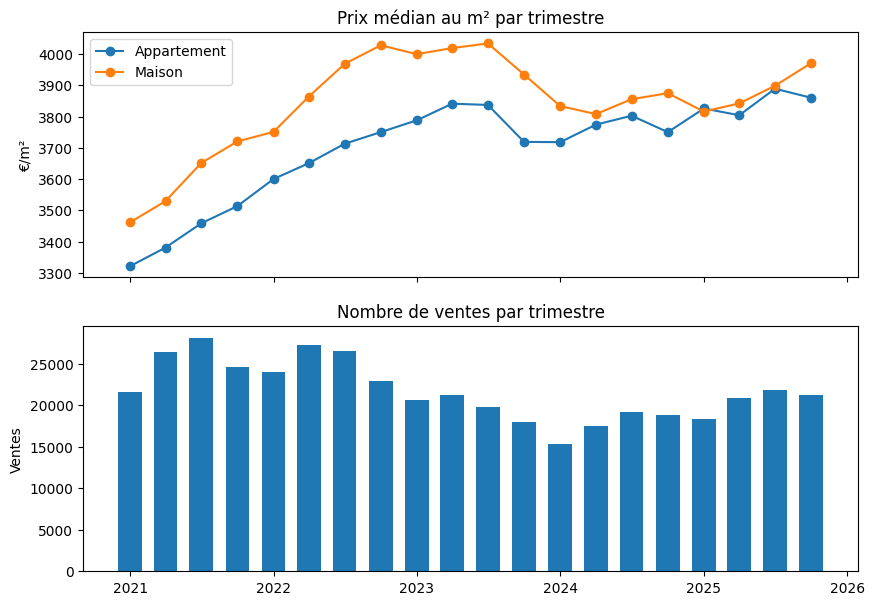

In [46]:
trimestre = logements["date_mutation"].dt.to_period("Q")
evolution = logements.groupby([trimestre, "type_local"])["prix_m2"].median().unstack()
volume = logements.groupby(trimestre).size()
evolution.index = evolution.index.to_timestamp()
volume.index = volume.index.to_timestamp()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for colonne in evolution.columns:
    ax1.plot(evolution.index, evolution[colonne], marker="o", label=colonne)
ax1.set(title="Prix médian au m² par trimestre", ylabel="€/m²")
ax1.legend()
ax2.bar(volume.index, volume.values, width=60)
ax2.set(title="Nombre de ventes par trimestre", ylabel="Ventes")
fig.savefig(dossier_fig / "evolution_temporelle.png", dpi=150, bbox_inches="tight")
plt.show()

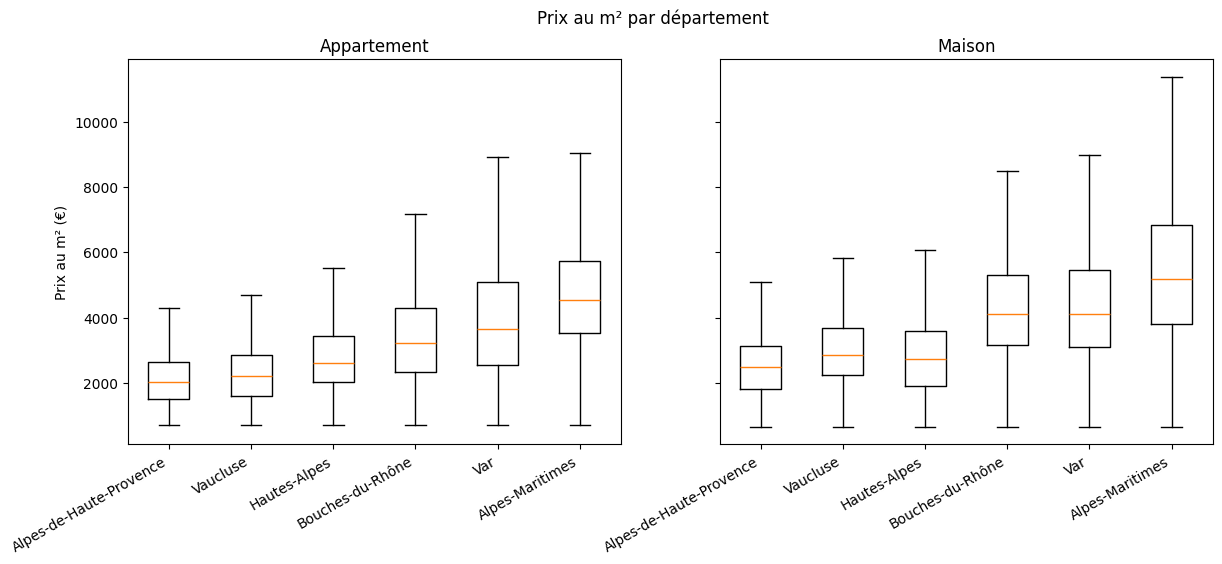

In [50]:
NOMS_DEP = {"04": "Alpes-de-Haute-Provence", "05": "Hautes-Alpes", "06": "Alpes-Maritimes",
            "13": "Bouches-du-Rhône", "83": "Var", "84": "Vaucluse"}

# zfill(2) remet le zéro devant si besoin : "4" devient "04"
logements["code_departement"] = logements["code_departement"].astype(str).str.zfill(2)
logements["departement"] = logements["code_departement"].map(NOMS_DEP)

logements["departement"].value_counts()
ordre = logements.groupby("departement")["prix_m2"].median().sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, type_local in zip(axes, ["Appartement", "Maison"]):
    sous = logements[logements["type_local"] == type_local]
    ax.boxplot([sous.loc[sous["departement"] == d, "prix_m2"] for d in ordre], showfliers=False)
    ax.set_xticks(range(1, len(ordre) + 1))
    ax.set_xticklabels(ordre, rotation=30, ha="right")
    ax.set_title(type_local)
axes[0].set_ylabel("Prix au m² (€)")
fig.suptitle("Prix au m² par département")
fig.savefig(dossier_fig / "prix_par_departement.png", dpi=150, bbox_inches="tight")
plt.show()

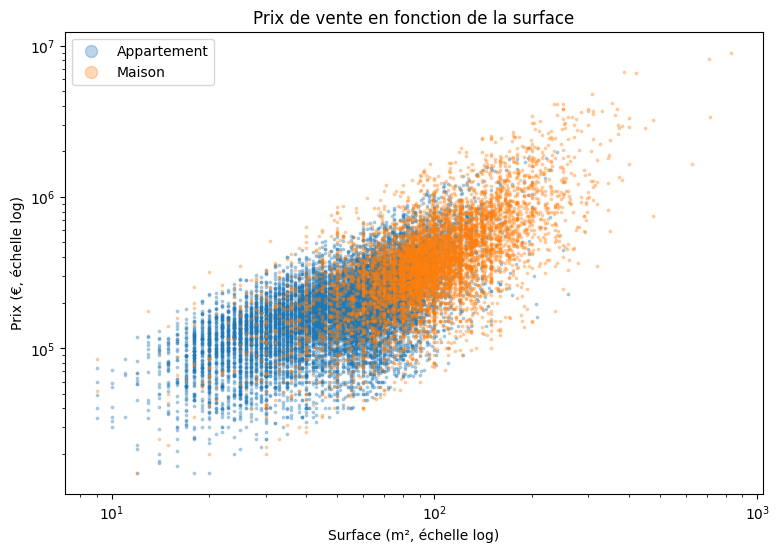

In [49]:
echantillon = logements.sample(20_000, random_state=42)

fig, ax = plt.subplots(figsize=(9, 6))
for type_local, couleur in [("Appartement", "tab:blue"), ("Maison", "tab:orange")]:
    s = echantillon[echantillon["type_local"] == type_local]
    ax.scatter(s["surface_reelle_bati"], s["valeur_fonciere"], s=3, alpha=0.3, color=couleur, label=type_local)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set(title="Prix de vente en fonction de la surface", xlabel="Surface (m², échelle log)",
       ylabel="Prix (€, échelle log)")
ax.legend(markerscale=5)
fig.savefig(dossier_fig / "surface_vs_prix.png", dpi=150, bbox_inches="tight")
plt.show()